In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import accuracy_score, confusion_matrix

In [4]:
df=pd.read_csv('Merge_data_v5_selected.csv')

In [5]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [6]:
del df['Unnamed: 0']

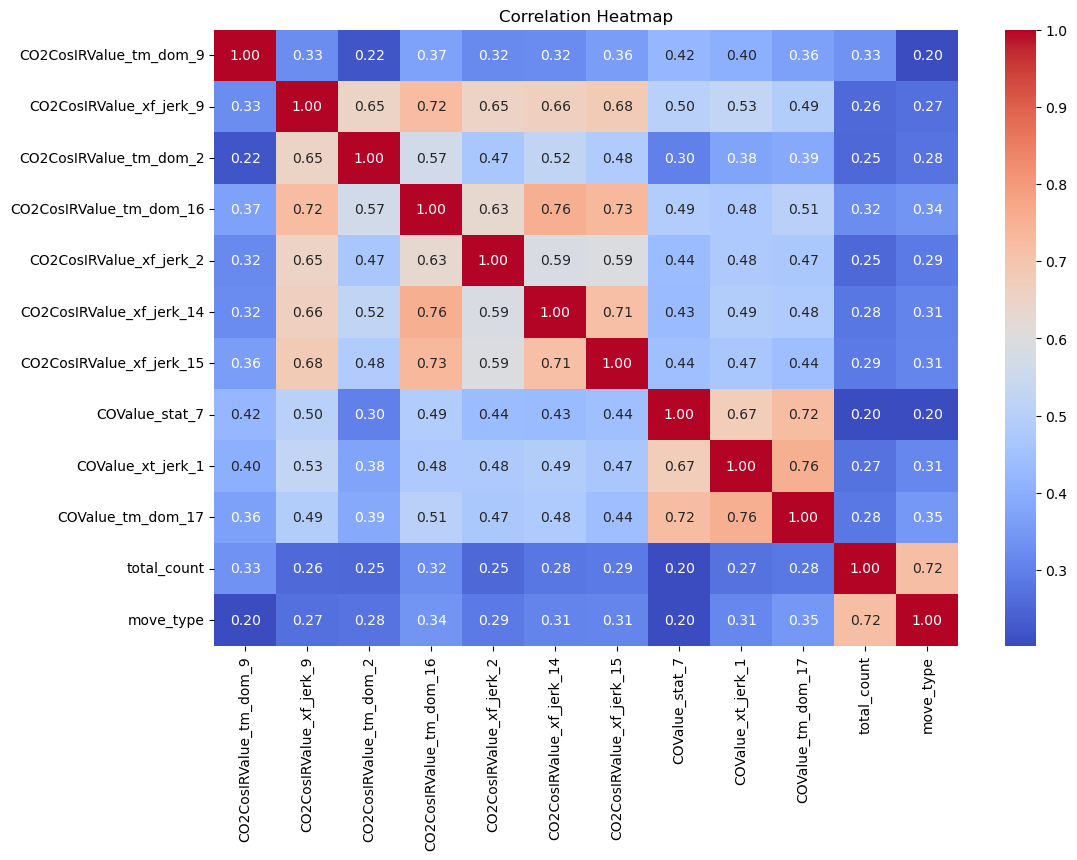

In [7]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [8]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [9]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
import xgboost as xgb
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    xgb_model = xgb.XGBClassifier(objective='multi:softmax',colsample_bytree=0.8,learning_rate=0.0001,max_depth=5,n_estimators=100,subsample=0.8, num_class=len(set(y)))
    xgb_model.fit(X_train,y_train)
    y_pred=xgb_model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [12]:
np.argmax(scores)

877

In [13]:
scores[np.argmax(scores)]

0.7505154639175258

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=877)

In [12]:
from sklearn.metrics import classification_report

In [122]:
model=xgb.XGBClassifier(objective='multi:softmax',colsample_bytree=0.8,learning_rate=0.0001,max_depth=5,n_estimators=100,subsample=0.8, num_class=len(set(y)))
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("Classification Report:\n", report)

Accuracy: 0.751
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.85      0.89       112
           1       0.61      0.30      0.40       113
           2       0.72      0.90      0.80       260

    accuracy                           0.75       485
   macro avg       0.75      0.68      0.70       485
weighted avg       0.74      0.75      0.73       485



In [14]:
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7618719889883001


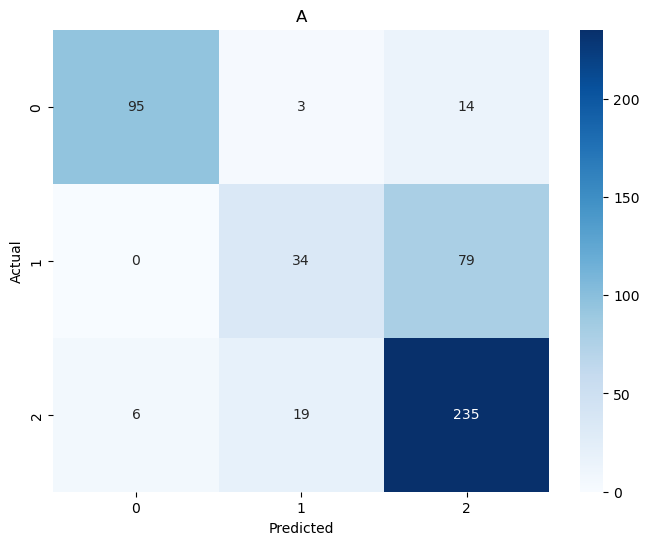

In [123]:
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('A')
plt.show()

In [208]:
Model=['Decision Tree','Logistic Reg.','Random Forest','XGboost']

In [209]:
df1=pd.DataFrame(Model)

In [210]:
df1

,0
0,Decision Tree
1,Logistic Reg.
2,Random Forest
3,XGboost


In [211]:
df1.rename(columns={0: 'Model'}, inplace=True)

In [212]:
df1

,Model
0,Decision Tree
1,Logistic Reg.
2,Random Forest
3,XGboost


In [213]:
df1['Raw']=[0.68,0.678,0.717,0.69]

In [214]:
df1['Rolling_mean']=[0.738,0.68,0.71,0.77]

In [215]:
df1['Sensor value predciction']=[0.75,0.72,0.781,0.75]

In [216]:
df1['Gaussian Filter']=[0.76,0.68,0.759,0.736]

In [217]:
df1

,Model,Raw,Rolling_mean,Sensor value predciction,Gaussian Filter
0,Decision Tree,0.680,0.738,0.750,0.760
1,Logistic Reg.,0.678,0.680,0.720,0.680
2,Random Forest,0.717,0.710,0.781,0.759
3,XGboost,0.690,0.770,0.750,0.736


In [183]:
df1

,Model,Sensor value predciction,Raw
0,Decision Tree,0.750,0.680
1,Logistic Reg.,0.720,0.678
2,Random Forest,0.781,0.717
3,XGboost,0.750,0.690


In [184]:
df1

,Model,Sensor value predciction,Raw
0,Decision Tree,0.750,0.680
1,Logistic Reg.,0.720,0.678
2,Random Forest,0.781,0.717
3,XGboost,0.750,0.690


In [69]:
df1.rename(columns={'Gaussian': 'Sensor value predciction'})

,Sensor value predciction,Raw,Rolling_mean
Model,,,
Decision Tree,0.720,0.723,0.738
Logistic Reg.,0.710,0.678,0.670
Random Forest,0.734,0.717,0.710
XGboost,0.750,0.730,0.720


In [224]:
del df1['Unnamed: 0']

In [220]:
df1.to_csv('accuracy.csv')

In [221]:
df1=pd.read_csv('accuracy.csv')

In [222]:
df1

,Unnamed: 0,Model,Raw,Rolling_mean,Sensor value predciction,Gaussian Filter
0,0,Decision Tree,0.680,0.738,0.750,0.760
1,1,Logistic Reg.,0.678,0.680,0.720,0.680
2,2,Random Forest,0.717,0.710,0.781,0.759
3,3,XGboost,0.690,0.770,0.750,0.736


In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

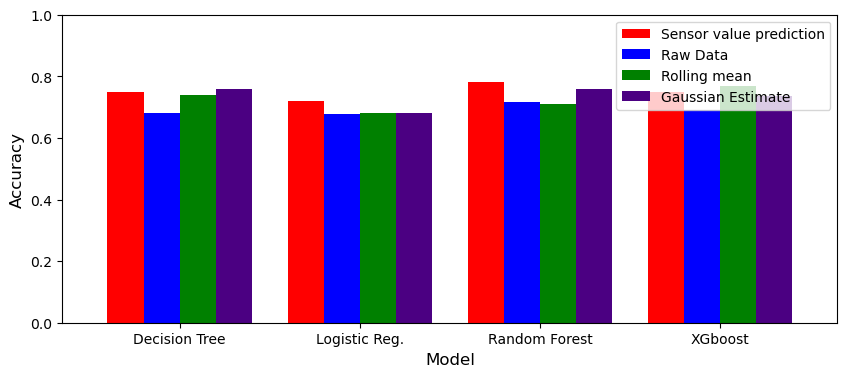

In [188]:
df1.set_index('Model', inplace=True)

# Define the colors for each column
colors = ['red', 'blue', 'green','indigo']
bar_width = 0.8
fig, ax = plt.subplots(figsize=(10, 4))
# Create the bar plot
ax = df1.plot(kind='bar', color=colors,width=bar_width,ax=ax)

# Set the x-axis label
ax.set_xlabel('Model',fontsize=12)
ax.set_ylabel('Accuracy',fontsize=12)
ax.set_xticklabels(df1.index, rotation=0)
ax.set_ylim([0,1])
legend_labels = ['Sensor value prediction', 'Raw Data', 'Rolling mean','Gaussian Estimate']
ax.legend(legend_labels,)
# Display the plot
plt.show()

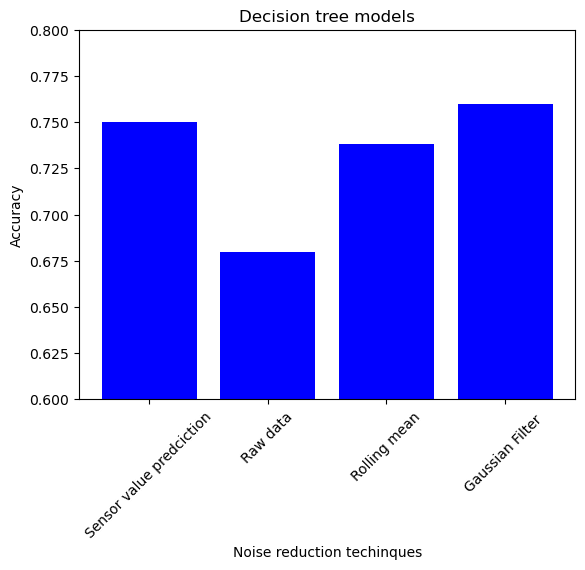

In [192]:
import matplotlib.pyplot as plt

# Sample data
categories = ['Sensor value predciction', 'Raw data', 'Rolling mean', 'Gaussian Filter ']
values = [0.750, 0.680, 0.738, 0.760]

# Create bar plot
plt.bar(categories, values, color='blue')

# Adding title and labels
plt.title('Decision tree models')
plt.xlabel('Noise reduction techinques')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.ylim(0.6, 0.8)
# Display the plot
plt.show()

In [226]:
del df1['Model']

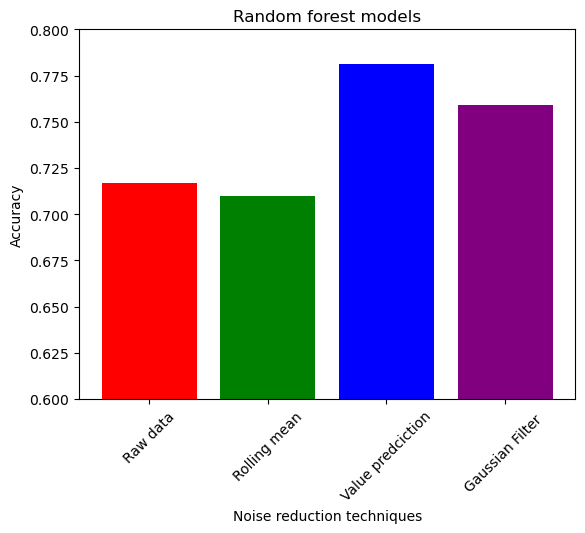

In [240]:
categories = ['Raw data', 'Rolling mean','Value predciction', 'Gaussian Filter ']
row_index = 2  # Choose the row index you want
y_values = df1.iloc[row_index].values
bar_colors = ['red', 'green', 'blue', 'purple']
# Create bar plot
plt.bar(categories, y_values, color=bar_colors)

# Adding title and labels
plt.title('Random forest models')
plt.xlabel('Noise reduction techniques')
plt.ylabel('Accuracy')
plt.ylim(0.6, 0.8)
# Rotate x-axis labels by 45 degrees
plt.xticks(rotation=45)

# Display the plot
plt.show()

In [219]:
y_values

array(['Random Forest', 0.717, 0.71, 0.781, 0.759], dtype=object)

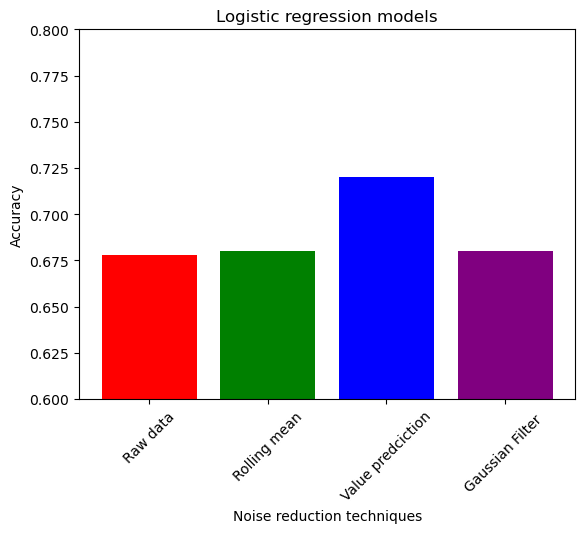

In [237]:
categories = ['Raw data', 'Rolling mean','Value predciction', 'Gaussian Filter ']
row_index = 1  # Choose the row index you want
y_values = df1.iloc[row_index].values
bar_colors = ['red', 'green', 'blue', 'purple']
# Create bar plot
plt.bar(categories, y_values, color=bar_colors)

# Adding title and labels
plt.title('Logistic regression models')
plt.xlabel('Noise reduction techniques')
plt.ylabel('Accuracy')
plt.ylim(0.6, 0.8)
# Rotate x-axis labels by 45 degrees
plt.xticks(rotation=45)

# Display the plot
plt.show()

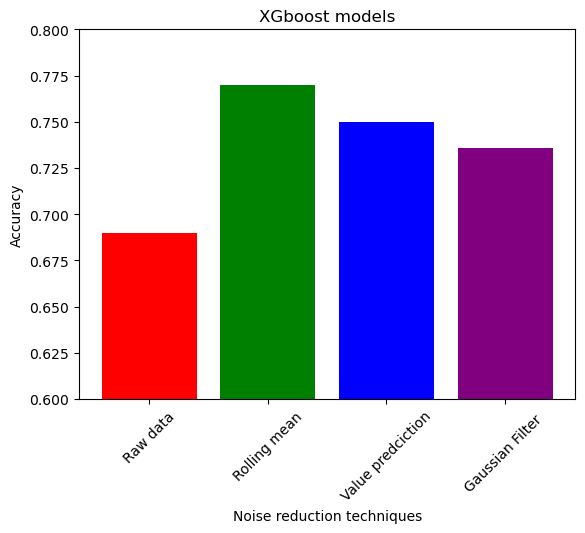

In [238]:
categories = ['Raw data', 'Rolling mean','Value predciction', 'Gaussian Filter ']
row_index = 3  # Choose the row index you want
y_values = df1.iloc[row_index].values
bar_colors = ['red', 'green', 'blue', 'purple']
# Create bar plot
plt.bar(categories, y_values, color=bar_colors)

# Adding title and labels
plt.title('XGboost models')
plt.xlabel('Noise reduction techniques')
plt.ylabel('Accuracy')
plt.ylim(0.6, 0.8)
# Rotate x-axis labels by 45 degrees
plt.xticks(rotation=45)

# Display the plot
plt.show()

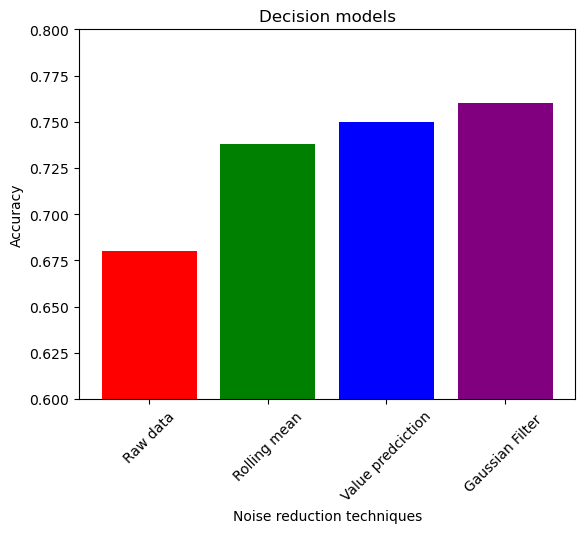

In [239]:
categories = ['Raw data', 'Rolling mean','Value predciction', 'Gaussian Filter ']
row_index = 0  # Choose the row index you want
y_values = df1.iloc[row_index].values
bar_colors = ['red', 'green', 'blue', 'purple']
# Create bar plot
plt.bar(categories, y_values, color=bar_colors)

# Adding title and labels
plt.title('Decision models')
plt.xlabel('Noise reduction techniques')
plt.ylabel('Accuracy')
plt.ylim(0.6, 0.8)
# Rotate x-axis labels by 45 degrees
plt.xticks(rotation=45)

# Display the plot
plt.show()